# Stop-validity review for routes 8 and 66: when the buses really moved, and whether they stopped at three corners

TODO.md Phase 1, Next, "Review the stop-validity windows against the archived GTFS". Exploratory, no spec. It follows
`notebooks/gtfs_history_routes_8_66.ipynb` (`docs/2026-11-22-gtfs-history-routes-8-66.md`), which found 26 of the 38
committed windows in `notebooks/routes_8_65_66_stop_validity.json` disagreeing with the schedule.

The owner's rules for the review (2026-11-23):

1. Where the pings date a change to a different service day than the schedule, the pings are ground truth: the actual
   driving is the schedule in effect that day.
2. A corner served at different spots under different stop ids, by pattern or by date, is one corner, served.
3. For the three corners the schedule leaves without a stop for a while (Orleans & Chicago on 6662 before 2025-09-28,
   Wells & Chicago on 6665 before 2025-11-23, `15341` on 9376 from 2025-08-17 to 2025-11-22), compare the time buses
   take from the stop before the corner to the stop after it, with and without a stop there.

Section 1 applies rule 1. The committed dates come from the longest `pdist` reported on each calendar day, a statistic
of a derived field; this reads where the buses were (lat/lon, observed) instead, and section 1b shows what set those
longest values.
Section 2 answers 3. Contains data from [Transitland](https://www.transit.land/terms): the paths and stop lists are
read from archived GTFS versions (ADR-013). Changes no window: it informs the review. Not for riders (ADR-002).

In [1]:
%matplotlib inline

import json
import re
import sys
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.csv as pacsv
from IPython.display import display

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from cta import mansueto_raw

_style = REPO_ROOT / "notebooks" / "cta_analysis.mplstyle"
if _style.is_file():
    plt.style.use(_style)
plt.rcParams["figure.dpi"] = 72  # keeps the committed notebook small
pd.set_option("display.max_rows", 200, "display.max_columns", 40, "display.width", 200)

RAW_DIR = REPO_ROOT / "data" / "mansueto_raw"  # Mansueto raw day CSVs, as scripts/route_run_level.py caches them
FEED_DIR = REPO_ROOT / "data" / "gtfs" / "feed_versions"  # from notebooks/gtfs_history_routes_8_66.ipynb section 1
VALIDITY = json.loads((REPO_ROOT / "notebooks" / "routes_8_65_66_stop_validity.json").read_text())
PIDS = ["9368", "9376", "6662", "6665"]
VERSION = {  # one archived version per path, each with clean shapes.txt distances for these pids
    "old": "78428dc43416f3a0be254cfcb2ea05ed2f65ebc9",   # fetched 2025-07-11: the routes before the closures
    "det1": "c07e68317b3e4452accfc9f09805727a88937458",  # fetched 2025-10-27: first detours (route 8 from 2025-08-17, 66 from 2025-09-28)
    "det2": "81c806bbfb678eb3e3a8292a0a83f768bdb1009d",  # fetched 2026-05-30: today's detours (from 2025-11-23)
}
SHAPE_ID = {"old": "673", "det1": "675", "det2": "679"}  # schedule-generation prefix in force on the sample days; pid = shape_id % 100,000
PATHS = {"9368": ["old", "det1", "det2"], "9376": ["old", "det1", "det2"], "6662": ["old", "det1"], "6665": ["old", "det1", "det2"]}  # 6662's 2025-11-23 change kept its path
FT_PER_DEG_LAT = 364_000.0  # local projection only
ON_PATH_FT = 100  # 2026-11-22 note: pings sit within 14 ft of their shape at the 95th percentile away from terminals

## Reading the paths and the raw days

A path is the GTFS shape of a pattern; the stops and their distances come from `stop_times.txt` (playbook, "GTFS
`shapes.txt` distances can run far past the last stop"; the three versions above are clean for these shapes). Raw day
files are fetched once into `data/mansueto_raw/` (about 40 MB each).

In [2]:
_STR = {c: pa.string() for c in ["route_id", "trip_id", "shape_id", "stop_id", "service_id"]}


def _read(z, name, cols=None):
    return pacsv.read_csv(z.open(name), convert_options=pacsv.ConvertOptions(column_types=_STR, include_columns=cols)).to_pandas()


SHAPES, PATTERN, STOPS = {}, {}, {}
for path, sha1 in VERSION.items():
    z = zipfile.ZipFile(FEED_DIR / f"{sha1}.zip")
    trips, shapes = _read(z, "trips.txt"), _read(z, "shapes.txt")
    st = _read(z, "stop_times.txt", ["trip_id", "stop_id", "stop_sequence", "shape_dist_traveled"])
    STOPS[path] = _read(z, "stops.txt").set_index("stop_id")
    for pid in PIDS:
        if path not in PATHS[pid]:
            continue
        shape_id = SHAPE_ID[path] + pid.zfill(5)
        trip = trips.loc[trips["shape_id"] == shape_id, "trip_id"].iloc[0]
        PATTERN[(path, pid)] = st[st["trip_id"] == trip].sort_values("stop_sequence")[["stop_id", "shape_dist_traveled"]].reset_index(drop=True)
        SHAPES[(path, pid)] = shapes[shapes["shape_id"] == shape_id].sort_values("shape_pt_sequence").reset_index(drop=True)
        assert abs(SHAPES[(path, pid)]["shape_dist_traveled"].max() - PATTERN[(path, pid)]["shape_dist_traveled"].max()) < 100


def project(shape: pd.DataFrame, lat, lon) -> tuple[np.ndarray, np.ndarray]:
    """Distance along the shape (feet, its own distances) of each point's projection, and the point's distance off it."""
    lat, lon = np.atleast_1d(lat).astype(float), np.atleast_1d(lon).astype(float)
    kx = FT_PER_DEG_LAT * np.cos(np.radians(41.9))
    x, y = shape["shape_pt_lon"].to_numpy() * kx, shape["shape_pt_lat"].to_numpy() * FT_PER_DEG_LAT
    d = shape["shape_dist_traveled"].to_numpy(float)
    ax, ay, vx, vy = x[:-1], y[:-1], np.diff(x), np.diff(y)
    seg2 = np.where(vx**2 + vy**2 == 0, 1e-9, vx**2 + vy**2)
    along, off = np.empty(len(lat)), np.empty(len(lat))
    for i in range(0, len(lat), 2000):
        px, py = (lon[i:i + 2000] * kx)[:, None], (lat[i:i + 2000] * FT_PER_DEG_LAT)[:, None]
        t = np.clip(((px - ax) * vx + (py - ay) * vy) / seg2, 0, 1)
        o2 = (ax + t * vx - px) ** 2 + (ay + t * vy - py) ** 2
        k = o2.argmin(axis=1)
        r = np.arange(len(k))
        along[i:i + 2000], off[i:i + 2000] = d[:-1][k] + t[r, k] * np.diff(d)[k], np.sqrt(o2[r, k])
    return along, off


def raw_day(day: str, pids=PIDS) -> pd.DataFrame:
    x = mansueto_raw.read_day(mansueto_raw.fetch_day(day, RAW_DIR), pids=pids)
    return x[x["data_date"] == day]  # each file also holds a few previous-day fixes

## 1. When the buses moved (rule 1)

For each day, the pings of each pid inside the area of the closures are classed by the paths they lie on (within
100 ft): only on the old path, only on the first detour, only on the second. A path-only count near zero while
another's is in the hundreds says which route the buses drove. *Section jumps* counts consecutive pings of one trip
that land on opposite sides of the closed section (Grand to Division for route 8, Grand to Chicago for route 66 west);
it is 0 to 22 on a normal day (a 300 s poll can straddle the 0.85 miles of route 8's section) and 32 to 101 when
Bus Tracker stops reporting buses while they cross it. Days were read around every change; the clean October days are section 2's.

In [3]:
AREA = {"lat": (41.884, 41.906), "lon": (-87.660, -87.628)}  # Halsted, Chicago Ave and the river between Lake and North Ave
SECTION = {"9368": (41.8913, 41.9036), "9376": (41.8913, 41.9036), "6665": (41.8913, 41.8966)}  # Grand to Division; Grand to Chicago
DRIVING_DAYS = ["2025-07-29", "2025-08-01", "2025-08-03", "2025-08-04", "2025-08-05", "2025-08-16", "2025-08-17",
                "2025-09-26", "2025-09-27", "2025-09-28", "2025-09-29", "2025-10-28", "2025-10-29", "2025-10-30",
                "2025-10-31", "2025-11-01", "2025-11-02", "2025-11-03", "2025-11-04", "2025-11-05", "2025-11-06",
                "2025-11-07", "2025-11-08", "2025-11-09", "2025-11-10", "2025-11-11", "2025-11-12", "2025-11-22",
                "2025-11-23", "2025-11-24", "2025-11-25"]
DRIVING_DAYS = sorted(set(DRIVING_DAYS) | {f"2025-08-{d:02d}" for d in range(6, 16)} | {f"2025-11-{d:02d}" for d in range(13, 22)})  # 2026-11-27: every day of the unreported periods


def section_jumps(g: pd.DataFrame, south: float, north: float) -> int:
    g = g.sort_values(["vehicle_id", "origtatripno", "vehicle_ts"])
    same = (g["vehicle_id"] == g["vehicle_id"].shift(-1)) & (g["origtatripno"] == g["origtatripno"].shift(-1))
    a, b = g["lat"].to_numpy(), g["lat"].shift(-1).to_numpy()
    return int((same.to_numpy() & (((a < south) & (b > north)) | ((a > north) & (b < south)))).sum())


rows = []
for day in DRIVING_DAYS:
    x = raw_day(day)
    for pid, g in x.groupby("pid"):
        box = g[g["lat"].between(*AREA["lat"]) & g["lon"].between(*AREA["lon"])]
        off = {p: project(SHAPES[(p, pid)], box["lat"], box["lon"])[1] for p in PATHS[pid]}
        r = {"day": day, "pid": pid}
        for p in PATHS[pid]:
            r[f"only_{p}"] = int(((off[p] < ON_PATH_FT) & np.all([off[o] >= ON_PATH_FT for o in PATHS[pid] if o != p], axis=0)).sum())
        r["section_jumps"] = section_jumps(g, *SECTION[pid]) if pid in SECTION else None
        rows.append(r)
DRIVING = pd.DataFrame(rows)
DRIVING["weekday"] = pd.to_datetime(DRIVING["day"]).dt.day_name().str[:3]
for pid in PIDS:
    print(pid)
    display(DRIVING[DRIVING["pid"] == pid].drop(columns="pid").set_index("day").dropna(axis=1, how="all"))

9368


,only_old,only_det1,section_jumps,only_det2,weekday
day,,,,,
2025-07-29,108,0,7.0,0.0,Tue
2025-08-01,123,0,5.0,0.0,Fri
2025-08-03,62,0,4.0,0.0,Sun
2025-08-04,18,4,67.0,0.0,Mon
2025-08-05,0,2,99.0,0.0,Tue
2025-08-06,0,5,87.0,0.0,Wed
2025-08-07,0,10,92.0,0.0,Thu
2025-08-08,0,5,76.0,0.0,Fri
2025-08-09,0,0,68.0,0.0,Sat


9376


,only_old,only_det1,section_jumps,only_det2,weekday
day,,,,,
2025-07-29,70,0,22.0,0.0,Tue
2025-08-01,70,0,18.0,0.0,Fri
2025-08-03,40,0,18.0,0.0,Sun
2025-08-04,18,2,67.0,0.0,Mon
2025-08-05,3,4,93.0,0.0,Tue
2025-08-06,0,4,92.0,0.0,Wed
2025-08-07,0,6,93.0,0.0,Thu
2025-08-08,1,0,66.0,0.0,Fri
2025-08-09,0,1,69.0,0.0,Sat


6662


,only_old,only_det1,weekday
day,,,
2025-07-29,173,0,Tue
2025-08-01,165,0,Fri
2025-08-03,98,0,Sun
2025-08-04,160,0,Mon
2025-08-05,199,0,Tue
2025-08-06,180,0,Wed
2025-08-07,160,0,Thu
2025-08-08,165,0,Fri
2025-08-09,129,0,Sat


6665


,only_old,only_det1,section_jumps,only_det2,weekday
day,,,,,
2025-07-29,143,0,0.0,0.0,Tue
2025-08-01,139,0,0.0,0.0,Fri
2025-08-03,92,0,0.0,0.0,Sun
2025-08-04,138,0,0.0,0.0,Mon
2025-08-05,144,0,0.0,0.0,Tue
2025-08-06,141,0,0.0,1.0,Wed
2025-08-07,136,0,0.0,0.0,Thu
2025-08-08,132,0,0.0,0.0,Fri
2025-08-09,106,0,0.0,0.0,Sat


The change dates three ways: the committed windows (the first calendar day whose longest `pdist` fits the new
pattern, `geometry_changes` in `notebooks/routes_8_65_66_pids.json`), the archived schedule (2026-11-22 note), and the
driving read above.

In [4]:
CHANGES = pd.DataFrame([
    # pattern, change, committed (first calendar day whose longest pdist fits the new pattern), schedule (GTFS), driving (this section), interim before it
    ("8 south (9368)", "first detour", "2025-08-17", "2025-08-17", "2025-08-17", "2025-08-04 to 08-16"),
    ("8 north (9376)", "first detour", "2025-08-17", "2025-08-17", "2025-08-17", "2025-08-04 to 08-16"),
    ("66 east (6662)", "detour", "2025-09-27", "2025-09-28", "2025-09-28", ""),
    ("66 west (6665)", "first detour", "2025-09-28", "2025-09-28", "2025-09-28", ""),
    ("8 north (9376)", "second detour", "2025-11-23", "2025-11-23", "2025-11-23", "2025-11-07 to 11-22"),
    ("66 west (6665)", "second detour", "2025-11-24", "2025-11-23", "2025-11-23", "2025-10-31 to 11-22"),
    ("8 south (9368)", "second detour", "2025-11-25", "2025-11-23", "2025-11-23", "2025-11-07 to 11-22"),
], columns=["pattern", "change", "committed", "schedule", "driving", "interim_unreported"])
display(CHANGES)

,pattern,change,committed,schedule,driving,interim_unreported
0,8 south (9368),first detour,2025-08-17,2025-08-17,2025-08-17,2025-08-04 to 08-16
1,8 north (9376),first detour,2025-08-17,2025-08-17,2025-08-17,2025-08-04 to 08-16
2,66 east (6662),detour,2025-09-27,2025-09-28,2025-09-28,
3,66 west (6665),first detour,2025-09-28,2025-09-28,2025-09-28,
4,8 north (9376),second detour,2025-11-23,2025-11-23,2025-11-23,2025-11-07 to 11-22
5,66 west (6665),second detour,2025-11-24,2025-11-23,2025-11-23,2025-10-31 to 11-22
6,8 south (9368),second detour,2025-11-25,2025-11-23,2025-11-23,2025-11-07 to 11-22


## 1b. What set the committed dates

`pdist` is derived: Bus Tracker projects the GPS fix onto the pattern it holds for the trip. On each of the four days
where the committed date and the driving date differ, each ping's GPS position is projected onto both candidate paths.
Where the paths have diverged by more than 1,000 ft, the test is which projection reproduces the reported `pdist`
within 200 ft. Then come the pings whose `pdist` exceeds the shorter pattern's length by more than 0.05 mi, the
pings that decide a "longest `pdist`" date.

In [5]:
CHANGEOVER = [("2025-09-27", "6662", "old", "det1"), ("2025-11-23", "6665", "det1", "det2"),
              ("2025-11-23", "9368", "det1", "det2"), ("2025-11-24", "9368", "det1", "det2")]
LENGTH_SLACK_FT = 0.05 * 5280  # the rule that dated geometry_changes: longest pdist within 0.05 mi of a pattern's length
fits, longest = [], []
for day, pid, a, b in CHANGEOVER:
    x = raw_day(day, [pid])
    pa, _ = project(SHAPES[(a, pid)], x["lat"], x["lon"])
    pb, _ = project(SHAPES[(b, pid)], x["lat"], x["lon"])
    past = np.abs(pa - pb) > 1_000
    ra, rb = (x["pdist"].to_numpy() - pa)[past], (x["pdist"].to_numpy() - pb)[past]
    fits.append({"day": day, "pid": pid, "pings where the paths differ": int(past.sum()),
                 f"pdist fits the earlier path": f"{(np.abs(ra) < 200).mean():.0%} ({a})", "pdist fits the later path": f"{(np.abs(rb) < 200).mean():.0%} ({b})"})
    shorter = min(PATTERN[(p, pid)]["shape_dist_traveled"].max() for p in (a, b))
    big = x["pdist"].to_numpy() > shorter + LENGTH_SLACK_FT
    for i in np.flatnonzero(big):
        longest.append({"day": day, "pid": pid, "local time": x["vehicle_ts"].iloc[i].tz_convert("America/Chicago").strftime("%H:%M"),
                        "vehicle": x["vehicle_id"].iloc[i], "trip": x["origtatripno"].iloc[i], "pdist": int(x["pdist"].iloc[i]),
                        "fits": a if abs(x["pdist"].iloc[i] - pa[i]) < abs(x["pdist"].iloc[i] - pb[i]) else b})
display(pd.DataFrame(fits))
display(pd.DataFrame(longest))

,day,pid,pings where the paths differ,pdist fits the earlier path,pdist fits the later path
0,2025-09-27,6662,888,100% (old),0% (det1)
1,2025-11-23,6665,66,0% (det1),100% (det2)
2,2025-11-23,9368,742,1% (det1),99% (det2)
3,2025-11-24,9368,1332,1% (det1),99% (det2)


,day,pid,local time,vehicle,trip,pdist,fits
0,2025-09-27,6662,23:24,2025,267694636,50160,det1
1,2025-11-23,6665,01:29,8682,267694801,49799,det1
2,2025-11-23,6665,01:34,8682,267694801,49799,det1
3,2025-11-23,6665,01:39,8682,267694801,49799,det1
4,2025-11-23,6665,01:44,8682,267694801,49819,det1
5,2025-11-23,9368,00:14,1287,267698789,81065,det1
6,2025-11-24,9368,19:49,1286,267681506,81548,det1


On all four days, 99% to 100% of `pdist` values fit the path the buses drove. So Bus Tracker measured along the right
geometry, and the day-or-two offsets come from the statistic. One trip set each committed date:
- **6662 on 2025-09-27:** the last old-route trip of the night (vehicle 2025) drove Chicago Avenue throughout, and its
  final ping at 23:24, at the east terminal both paths share, reports a detour-pattern `pdist`.
- **6665 and 9368 on 2025-11-23:** an owl trip just after midnight that belongs to the previous service day (the raw
  files are calendar days, playbook gotcha) was still, rightly, on the old pattern.
- **9368 on 2025-11-24:** one evening trip (vehicle 1286) was measured along the old pattern for its whole run and went
  unreported through the detour section, while every other trip that day was measured along today's detour.

## 2. Did the buses stop at the three corners? (rule 3)

Pings come about every 300 s, so one trip's time over a few hundred feet cannot be read off its pings. The average
can: a ping is a sample in time, so where buses spend time, pings pile up. Each ping stands for the time to the
midpoints of its neighbours on the same trip (each half capped at 330 s, so a missed poll counts once); summed over a
stretch of road and divided by the trips that crossed it, that is the **mean seconds a trip spends there**. A stop
where buses dwell shows as a pile-up at the stop; free-flowing road as almost nothing.

Positions are `pdist` minus the corner's distance along that period's path (the corner stop's position projected onto
the path), so 0 is the corner in every panel. Three periods of ten clean weekdays each (Tue to Thu, no interim day):
the old routes (July 2025), the first detours (October 2025) and today's detours (June 2026, same season as the
first).

In [6]:
PERIOD_DAYS = {
    "old": ["2025-07-08", "2025-07-09", "2025-07-10", "2025-07-15", "2025-07-16", "2025-07-17", "2025-07-22", "2025-07-23", "2025-07-24", "2025-07-29"],
    "det1": ["2025-10-07", "2025-10-08", "2025-10-09", "2025-10-14", "2025-10-15", "2025-10-16", "2025-10-21", "2025-10-22", "2025-10-23", "2025-10-28"],
    "det2": ["2026-06-09", "2026-06-10", "2026-06-11", "2026-06-16", "2026-06-17", "2026-06-18", "2026-06-23", "2026-06-24", "2026-06-25", "2026-06-30"],
}
PERIOD_LABEL = {"old": "old route (Jul 2025)", "det1": "first detour (Oct 2025)", "det2": "today's detour (Jun 2026)"}
CORNERS = [("6662", "6714"), ("6665", "18803"), ("9376", "15341")]  # (pid, the stop id at the corner today)
CORNER_PATH = {"6662": "det1", "6665": "det2", "9376": "det2"}  # the path that has the corner stop today (6662 has no det2 entry)
HALF_GAP_CAP_S = 330  # a poll is ~300 s (240 to 360 after minute truncation); a missed poll's half-gap stays one poll
REACH_FT = 1_500  # a trip counts when it has pings this far before and after the corner
CORNER_FT = 150  # dwell pile-ups sit from 160 ft before to 70 ft after a stop's pdist (pdist trails position ~50 ft; near-side stops)
BIN_FT = 50
AT_CORNER_FT = 100  # a pattern stop this close is the corner's own stop (the corner stops measured sit 0 to 92 ft off; Franklin, 146 ft past Orleans on 6662's old path, is not)


def ping_weights(p: pd.DataFrame) -> pd.DataFrame:
    p = p.sort_values(["vehicle_id", "origtatripno", "vehicle_ts"]).copy()
    p["trip"] = p["data_date"] + "|" + p["vehicle_id"] + "|" + p["origtatripno"]
    t = (p["vehicle_ts"] - pd.Timestamp("1970-01-01", tz="UTC")).dt.total_seconds()
    prev = (t.groupby(p["trip"]).diff() / 2).clip(upper=HALF_GAP_CAP_S)
    nxt = (-t.groupby(p["trip"]).diff(-1) / 2).clip(upper=HALF_GAP_CAP_S)
    p["w"] = prev.fillna(nxt).fillna(0) + nxt.fillna(prev).fillna(0)
    return p


PINGS = {per: pd.concat([ping_weights(raw_day(d, ["6662", "6665", "9376"])) for d in days], ignore_index=True)
         for per, days in PERIOD_DAYS.items()}
TODAY_STOPS = STOPS["det2"]


def corner_position(pid: str, per: str, stop_id: str) -> float:
    s = TODAY_STOPS.loc[stop_id]
    along, off = project(SHAPES[(per, pid)], s["stop_lat"], s["stop_lon"])
    return float(along[0])


def traversals(pid: str, per: str, at: float) -> pd.DataFrame:
    p = PINGS[per]
    p = p[p["pid"] == pid].assign(x=lambda d: d["pdist"] - at)
    reach = p.groupby("trip")["x"].agg(["min", "max"])
    ok = reach[(reach["min"] < -REACH_FT) & (reach["max"] > REACH_FT)].index
    return p[p["trip"].isin(ok)], len(ok)


def seconds_in(p: pd.DataFrame, n: int, lo: float, hi: float) -> tuple[float, float]:
    """Mean seconds per trip with pdist in [lo, hi) relative to the corner, and its standard error over trips."""
    per_trip = p[(p["x"] >= lo) & (p["x"] < hi)].groupby("trip")["w"].sum().reindex(p["trip"].unique(), fill_value=0)
    return per_trip.mean(), per_trip.std(ddof=1) / np.sqrt(n)


def nearby_stops(pid: str, per: str, at: float, reach: float = 1_300) -> pd.DataFrame:
    s = PATTERN[(per, pid)].assign(x=lambda d: d["shape_dist_traveled"] - at)
    s = s[s["x"].abs() <= reach].copy()
    s["name"] = s["stop_id"].map(STOPS[per]["stop_name"])
    return s[["stop_id", "name", "x"]]


def profile(p: pd.DataFrame, n: int) -> pd.Series:
    """Mean seconds per trip in each 50 ft of pdist from -1,200 to +1,200 ft around the corner (bins by their start)."""
    q = p[p["x"].between(-1_200, 1_200, inclusive="left")]
    return (q.groupby((q["x"] // BIN_FT) * BIN_FT)["w"].sum() / n).reindex(np.arange(-1_200, 1_200, BIN_FT), fill_value=0)


rows, PROFILES = [], {}
for pid, corner in CORNERS:
    for per in PERIOD_DAYS:
        if per not in PATHS[pid]:
            per_path = "det1"  # 6662: today's path is the first detour's
        else:
            per_path = per
        at = corner_position(pid, per_path, corner)
        p, n = traversals(pid, per, at)
        stops = nearby_stops(pid, per_path, at)
        here = stops[stops["x"].abs() <= AT_CORNER_FT]
        before, after = stops[stops["x"] < -AT_CORNER_FT].iloc[-1], stops[stops["x"] > AT_CORNER_FT].iloc[0]
        c_mean, c_se = seconds_in(p, n, -CORNER_FT, CORNER_FT)
        s_mean, s_se = seconds_in(p, n, before["x"] + 75, after["x"] - 175)
        prof = profile(p, n)
        rows.append({"pid": pid, "corner": TODAY_STOPS.loc[corner, "stop_name"], "period": per, "trips": n,
                     "stop at the corner": ", ".join(here["stop_id"]) or "none",
                     "corner_s": round(c_mean, 1), "corner_se": round(c_se, 1),
                     "corner_peak_s": round(prof[(prof.index >= -CORNER_FT) & (prof.index < CORNER_FT)].max(), 1),
                     "stop_before": f"{before['name']} ({before['x']:+.0f} ft)", "stop_after": f"{after['name']} ({after['x']:+.0f} ft)",
                     "between_s": round(s_mean, 1), "between_se": round(s_se, 1)})
        PROFILES[(pid, per)] = (prof, stops)
CORNER_TABLE = pd.DataFrame(rows)
display(CORNER_TABLE)

,pid,corner,period,trips,stop at the corner,corner_s,corner_se,corner_peak_s,stop_before,stop_after,between_s,between_se
0,6662,Orleans & Chicago,old,1626,none,24.3,2.0,13.8,Chicago & Hudson (-913 ft),Chicago & Franklin (Brown line) (+146 ft),39.7,2.5
1,6662,Orleans & Chicago,det1,1460,6714,58.7,3.1,19.1,Orleans & Huron (-634 ft),Chicago & Franklin (Brown line) (+302 ft),62.2,3.2
2,6662,Orleans & Chicago,det2,1599,6714,52.3,2.9,19.6,Orleans & Huron (-634 ft),Chicago & Franklin (Brown line) (+302 ft),79.4,3.3
3,6665,Wells & Chicago,old,1591,none,7.7,1.2,3.9,Chicago & LaSalle (-321 ft),Chicago & Franklin (Brown line) (+305 ft),14.7,1.6
4,6665,Wells & Chicago,det1,1389,none,4.9,1.0,1.9,Chicago & LaSalle (-321 ft),Chicago & Franklin (Brown line) (+305 ft),12.5,1.6
5,6665,Wells & Chicago,det2,1583,18803,41.7,2.6,27.9,Chicago & Clark (-920 ft),Wells & Huron (+412 ft),117.1,3.8
6,9376,Milwaukee & Grand/Halsted (Blue Line),old,965,15274,17.7,2.3,13.9,Halsted & Hubbard (-463 ft),Halsted & Erie (+805 ft),105.5,4.7
7,9376,Milwaukee & Grand/Halsted (Blue Line),det1,895,none,15.1,2.2,5.4,Halsted & Hubbard (-338 ft),Grand & Union (+346 ft),52.2,3.8
8,9376,Milwaukee & Grand/Halsted (Blue Line),det2,944,15341,40.8,3.4,26.8,Halsted & Hubbard (-458 ft),Milwaukee & Erie (+1119 ft),93.1,4.6


`between_s` is the owner's measure: the mean time from the stop before the corner to the stop after it, leaving out
the 75 ft after the stop before and the 175 ft before the stop after, where those stops' own dwell falls. It moves
with the path as well as with the stop, because each detour changed the street the corner sits on. On 6662's old
route the stop after (Chicago & Franklin) is only 146 ft past the corner, so its window ends before the corner.
`corner_s` (the corner ±150 ft) is the local measure, the same window in every period. `corner_peak_s` is the largest
single 50 ft stretch inside it: a dwell concentrates in one or two stretches at the stop, while a slow turn or a
moving queue spreads out (added 2026-11-27, when the map in section 2b showed that the totals mix the two).

**Control for a signal.** Orleans & Chicago is a signalled intersection, and a bus queueing at a red light piles up
pings as a stop does. Route 66 westbound crosses the same intersection on Chicago Avenue and never had a stop there:
the same window around that crossing says what the signal alone costs.

In [7]:
ctrl = []
for per in ["old", "det1"]:
    at = corner_position("6665", per, "6714")  # Orleans & Chicago projected onto route 66 westbound's Chicago Avenue
    p, n = traversals("6665", per, at)
    m, se = seconds_in(p, n, -CORNER_FT, CORNER_FT)
    prof = profile(p, n)
    stops = nearby_stops("6665", per, at, 400)
    ctrl.append({"pattern": "66 west (6665), Orleans crossing", "period": per, "trips": n, "stop within 150 ft": ", ".join(stops.loc[stops["x"].abs() <= CORNER_FT, "stop_id"]) or "none",
                 "corner_s": round(m, 1), "corner_se": round(se, 1),
                 "corner_peak_s": round(prof[(prof.index >= -CORNER_FT) & (prof.index < CORNER_FT)].max(), 1)})
display(pd.DataFrame(ctrl))

,pattern,period,trips,stop within 150 ft,corner_s,corner_se,corner_peak_s
0,"66 west (6665), Orleans crossing",old,1592,none,23.3,2.0,18.1
1,"66 west (6665), Orleans crossing",det1,1389,none,27.6,2.3,22.9


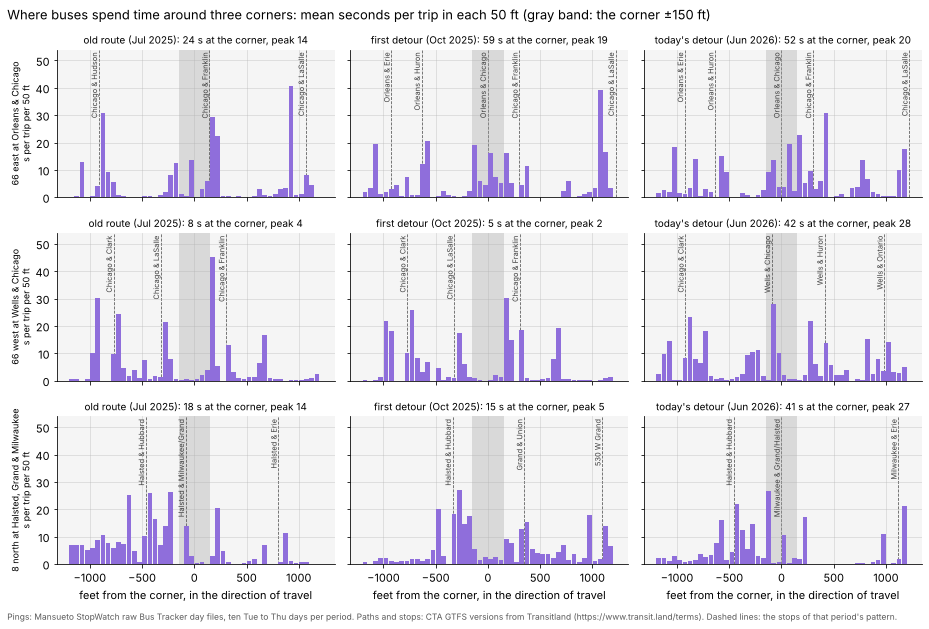

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(13, 8.6), sharex=True, sharey=True)
TITLE = {"6662": "66 east at Orleans & Chicago", "6665": "66 west at Wells & Chicago", "9376": "8 north at Halsted, Grand & Milwaukee"}
for i, (pid, corner) in enumerate(CORNERS):
    for j, per in enumerate(PERIOD_DAYS):
        ax = axes[i, j]
        prof, stops = PROFILES[(pid, per)]
        ax.axvspan(-CORNER_FT, CORNER_FT, color="0.85", lw=0, zorder=0)
        ax.bar(prof.index + BIN_FT / 2, prof.values, width=BIN_FT * 0.9, color="C0", zorder=2)
        for s in stops.itertuples():
            ax.axvline(s.x, color="0.35", lw=0.8, ls="--", zorder=1)
            ax.text(s.x, 53, s.name.replace(" (Blue Line)", "").replace(" (Brown line)", ""), rotation=90, fontsize=7.5,
                    va="top", ha="right", color="0.25")
        row = CORNER_TABLE[(CORNER_TABLE["pid"] == pid) & (CORNER_TABLE["period"] == per)].iloc[0]
        ax.set_ylim(0, 54)
        ax.set_title(f"{PERIOD_LABEL[per]}: {row['corner_s']:.0f} s at the corner, peak {row['corner_peak_s']:.0f}", fontsize=10)
        if j == 0:
            ax.set_ylabel(f"{TITLE[pid]}\ns per trip per 50 ft", fontsize=9)
        if i == 2:
            ax.set_xlabel("feet from the corner, in the direction of travel")
fig.suptitle("Where buses spend time around three corners: mean seconds per trip in each 50 ft (gray band: the corner ±150 ft)",
             x=0.01, ha="left", fontsize=13)
fig.text(0.01, -0.01, "Pings: Mansueto StopWatch raw Bus Tracker day files, ten Tue to Thu days per period. Paths and stops: CTA GTFS "
         "versions from Transitland (https://www.transit.land/terms). Dashed lines: the stops of that period's pattern.", fontsize=8.5, color="0.35")
fig.tight_layout()
plt.show()

### 2b. The Halsted, Grand & Milwaukee corner on a map

Route 8 northbound near stop `15341`, in feet east and north of that stop, at equal scale. Gray: every CTA bus path
of the old and today's schedules nearby, standing in for the streets. Purple line: route 8 northbound's path in
that period's schedule. Bubbles: the profile's bars, mean seconds per trip in each 50 ft stretch, placed along the path
(positions good to about 100 ft: GTFS stop distances and projected stop positions differ by up to 90 ft, and `pdist`
trails the GPS position by about 50 ft). Orange: the ±150 ft band measured in each period. Dashed circle: 150 ft around
stop `15341`.

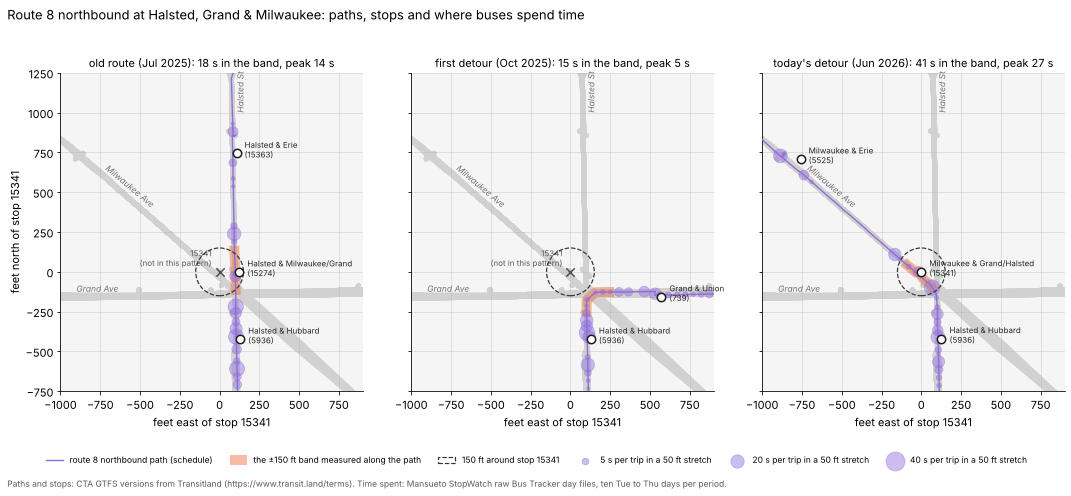

In [9]:
MAP_X, MAP_Y = (-1_000, 900), (-750, 1_250)  # feet around stop 15341: Hubbard to the south, Erie to the north, Union to the east
here = TODAY_STOPS.loc["15341"]
KX = FT_PER_DEG_LAT * np.cos(np.radians(41.9))


def map_xy(lat, lon):
    return (np.asarray(lon, float) - here["stop_lon"]) * KX, (np.asarray(lat, float) - here["stop_lat"]) * FT_PER_DEG_LAT


backdrop = []
for path in ("old", "det2"):
    z = zipfile.ZipFile(FEED_DIR / f"{VERSION[path]}.zip")
    trips, shapes = _read(z, "trips.txt"), _read(z, "shapes.txt")
    bus = set(trips.loc[trips["route_id"].str.fullmatch(r"\d+"), "shape_id"])
    near = shapes[shapes["shape_id"].isin(bus) & shapes["shape_pt_lat"].between(here["stop_lat"] - 0.006, here["stop_lat"] + 0.006)
                  & shapes["shape_pt_lon"].between(here["stop_lon"] - 0.008, here["stop_lon"] + 0.008)]
    backdrop.append(shapes[shapes["shape_id"].isin(set(near["shape_id"]))].assign(shape_id=lambda d, p=path: p + d["shape_id"]))
BACKDROP = pd.concat(backdrop).sort_values(["shape_id", "shape_pt_sequence"])

fig, axes = plt.subplots(1, 3, figsize=(15, 6.6), sharex=True, sharey=True)
for ax, per in zip(axes, PERIOD_DAYS):
    for _, g in BACKDROP.groupby("shape_id"):
        ax.plot(*map_xy(g["shape_pt_lat"], g["shape_pt_lon"]), color="0.82", lw=5, solid_capstyle="round", zorder=0)
    shape, pattern, stops = SHAPES[(per, "9376")], PATTERN[(per, "9376")], STOPS[per]
    sx, sy = map_xy(shape["shape_pt_lat"], shape["shape_pt_lon"])
    dist = shape["shape_dist_traveled"].to_numpy(float)
    ax.plot(sx, sy, color="C0", lw=1.4, zorder=3, label="route 8 northbound path (schedule)")
    at = corner_position("9376", per, "15341")
    band = np.linspace(at - CORNER_FT, at + CORNER_FT, 60)
    ax.plot(np.interp(band, dist, sx), np.interp(band, dist, sy), color="C1", lw=10, alpha=0.45, solid_capstyle="butt", zorder=2,
            label="the ±150 ft band measured along the path")
    prof, _ = PROFILES[("9376", per)]
    centres = prof.index.to_numpy() + BIN_FT / 2 + at
    bx, by = np.interp(centres, dist, sx), np.interp(centres, dist, sy)
    keep = (bx > MAP_X[0]) & (bx < MAP_X[1]) & (by > MAP_Y[0]) & (by < MAP_Y[1]) & (prof.to_numpy() >= 1)
    ax.scatter(bx[keep], by[keep], s=prof.to_numpy()[keep] * 9, color="C0", alpha=0.45, edgecolor="C0", lw=0.8, zorder=4)
    ax.add_patch(plt.Circle((0, 0), CORNER_FT, fill=False, ls="--", lw=1.2, color="0.2", zorder=5, label="150 ft around stop 15341"))
    for s in pattern["stop_id"]:
        x, y = map_xy(stops.loc[s, "stop_lat"], stops.loc[s, "stop_lon"])
        if MAP_X[0] < x < MAP_X[1] and MAP_Y[0] < y < MAP_Y[1]:
            ax.scatter(x, y, s=70, color="white", edgecolor="0.1", lw=1.5, zorder=6)
            ax.annotate(f"{stops.loc[s, 'stop_name'].replace(' (Blue Line)', '')}\n({s})", (x, y), xytext=(8, -4),
                        textcoords="offset points", fontsize=8, color="0.15", zorder=7)
    if "15341" not in set(pattern["stop_id"]):
        ax.scatter(0, 0, s=70, marker="x", color="0.3", lw=1.5, zorder=6)
        ax.annotate("15341\n(not in this pattern)", (0, 0), xytext=(-8, 6), textcoords="offset points", fontsize=8, color="0.35", ha="right")
    for txt, (tx, ty), rot in [("Halsted St", (150, 1000), 90), ("Grand Ave", (-900, -125), 0), ("Milwaukee Ave", (-720, 645), -40)]:
        ax.text(tx, ty, txt, rotation=rot, fontsize=8.5, color="0.45", style="italic", rotation_mode="anchor")
    row = CORNER_TABLE[(CORNER_TABLE["pid"] == "9376") & (CORNER_TABLE["period"] == per)].iloc[0]
    ax.set_title(f"{PERIOD_LABEL[per]}: {row['corner_s']:.0f} s in the band, peak {row['corner_peak_s']:.0f} s", fontsize=11)
    ax.set_xlim(*MAP_X); ax.set_ylim(*MAP_Y); ax.set_aspect("equal")
    ax.set_xlabel("feet east of stop 15341")
axes[0].set_ylabel("feet north of stop 15341")
for secs in (5, 20, 40):
    axes[0].scatter([], [], s=secs * 9, color="C0", alpha=0.45, edgecolor="C0", lw=0.8, label=f"{secs} s per trip in a 50 ft stretch")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=6, fontsize=8.5, frameon=False, bbox_to_anchor=(0.5, 0.0))
fig.suptitle("Route 8 northbound at Halsted, Grand & Milwaukee: paths, stops and where buses spend time", x=0.01, ha="left", fontsize=13)
fig.text(0.01, -0.03, "Paths and stops: CTA GTFS versions from Transitland (https://www.transit.land/terms). Time spent: Mansueto StopWatch "
         "raw Bus Tracker day files, ten Tue to Thu days per period.", fontsize=8.5, color="0.35")
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

What the map shows. Grand Avenue crosses Halsted about 130 ft south of stop `15341`.
- **Old route:** the stop (`15274`) stood on the far side, about 130 ft north of Grand. Its dwell is the 14 s stretch
  at the stop, inside the band. The 40 s just south of Grand is the queue for the signal.
- **First detour:** buses queued from the Hubbard stop up to Grand, turned right, and next piled up approaching
  Grand & Union. Inside the band no stretch holds more than 5 s.
- **Today's detour:** the band holds 27 s just past the intersection and 11 s at the stop.

## Findings

Measured 2026-11-23 and 2026-11-27 from Mansueto raw day files (300 s pings; 50 days around the changes, 30 sample
weekdays) and three archived CTA GTFS versions. Contains data from [Transitland](https://www.transit.land/terms).
Recorded in `docs/2026-11-23-stop-validity-review-driving-and-corners.md`, `docs/2026-11-23-longest-pdist-dating.md`
and `docs/2026-11-27-corner-map-and-unreported-days.md`.

1. **Rule 1: the actual driving matches the schedule's dates; the committed dates are a day or two off because of how
   they were measured.** Route 66 east left Chicago Avenue on 2025-09-28 (147 pings on the old path on 09-27, 1 after
   midnight on 09-28), not 09-27. Route 66 west and route 8 south took today's detours on 2025-11-23 (100 to 109 pings
   a pid on today's-detour-only streets that day, against 2 to 11 the day before), not 2025-11-24 and 2025-11-25. The other four changes agree
   all three ways. The committed dates came from each calendar day's longest `pdist`, and one trip set each of the
   three that differ (section 1b): a final ping at the terminal already on the new pattern (6662), an owl trip of the
   previous service day after midnight (6665, 9368), and one evening trip measured along the old pattern (9368, 11-24).
   Bus Tracker otherwise measured `pdist` along the path driven (99% to 100% of pings). Under rule 1, 18 committed
   windows move: 6662's eight stops to 2025-09-28 (from 09-27), 6665's
   `6613`, `6614`, `5020`, `769` to 2025-11-23 (from 11-24), and 9368's six Division and Milwaukee stops to 2025-11-23
   (from 11-25).
2. **Before three of the changes, Bus Tracker stopped reporting buses on the closed section.** Route 8 from 2025-08-04
   (the Halsted closure; the buses left Halsted that day) to 2025-08-16, route 8 again from 2025-11-07 to 2025-11-22,
   and route 66 west from 2025-10-31 to 2025-11-22. Every day of the three periods was read (the 19 days skipped on
   2026-11-23 were added on 2026-11-27): 32 to 102 consecutive ping pairs per pid jump the section each day (0 to 22 on
   the other days read), 10 to 20 minutes apart, and almost no ping lies on any of the three paths there; route 66 west
   has 3 to 35 a day on Wells. Rule 1 has nothing to read on those days, and Mansueto's arrivals at stops in the
   section are interpolated across the gap.
3. **Rule 3, Wells & Chicago (6665 `18803`): not served before the detour reached Wells.** Westbound buses spent
   7.7 ± 1.2 s (old route) and 4.9 ± 1.0 s (first detour) within 150 ft of the corner, against 41.7 ± 2.6 s once the
   stop existed. The pile-ups sit at Chicago & LaSalle and Chicago & Franklin, on either side.
4. **Rule 3, Orleans & Chicago (6662 `6714`): not served before 2025-09-28.** Eastbound buses on Chicago Avenue spent
   24.3 ± 2.0 s at the corner. Westbound buses crossing the same intersection, which never had a stop there, spent
   23.3 ± 2.0 and 27.6 ± 2.3 s, so that is the signal. With the stop, 58.7 ± 3.1 and 52.3 ± 2.9 s.
5. **Rule 3, Halsted, Grand & Milwaukee (9376 `15341`): no dwell at the corner during the first detour.** Northbound
   buses spent 15.1 ± 2.2 s within 150 ft of it, spread over the right turn: no 50 ft stretch held more than 5 s. With a
   stop, one stretch holds the dwell: 14 s at the old far-side stop (`15274`, 17.7 s in the band) and 27 s at today's
   (40.8 s in the band). The map (section 2b) shows that the 40 s pile-up 90 to 125 ft south of Grand on the old route
   is the signal queue, not the old stop, which the 2026-11-23 reading had confused. With the schedule (no stop between
   Hubbard, 338 ft before, and Grand & Union, 346 ft after), the reading is not served from 2025-08-17 to 2025-11-22.
6. **The stop-before-to-stop-after times move with the path, not only with the stop.** LaSalle to Franklin on Chicago
   Avenue takes 14.7 and 12.5 s on average (no stop at Wells); today's Clark to Wells & Huron, which turns onto Wells,
   117.1 s. They agree with the corner readings but cannot settle them alone: each corner's stop arrived with a new
   path.
7. **What the review changes** (applied through `specs/mansueto-stop-validity.md`, Rule 2). Confirmed by the owner on
   2026-11-27:
   - the 18 dates of finding 1;
   - new windows for `6714` (from 2025-09-28) and `18803` (from 2025-11-23);
   - the five id changes at a served corner keep their windows (rule 2).

   Still open:
   - `15341` on 9376 not served from 2025-08-17 to 2025-11-22, inside a stop that is otherwise served;
   - what to do with the unreported days of finding 2.